In [1]:
# %pip install pandas matplotlib
# %pip install matplotlib
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# 1. Load the clean interim dataset
DATA_PATH = r"C:\Users\KARTIK\OneDrive\Desktop\Master folder\Traffic flow project\data\interim\delhi_15min_density.parquet"
df = pd.read_parquet(DATA_PATH)

In [3]:
# 2. Group by the time of day to get the 40-day average for each 15-minute slot
diurnal_avg = df.groupby(df.index.time)[
    ["Approach1_Queue", "Approach2_Queue", "Approach3_Queue"]
].mean()

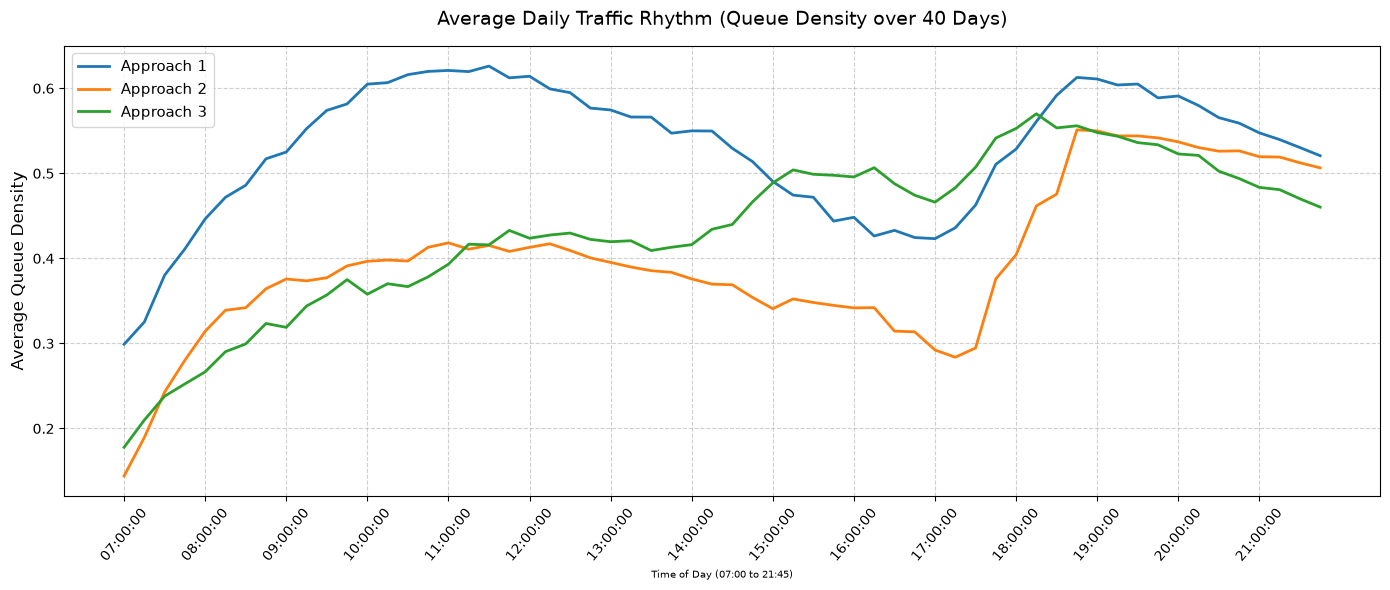

In [8]:
# 3. Plot the diurnal curves
plt.figure(figsize=(14, 6))

plt.plot(diurnal_avg.index.astype(str), diurnal_avg["Approach1_Queue"], label="Approach 1", linewidth=2)
plt.plot(diurnal_avg.index.astype(str), diurnal_avg["Approach2_Queue"], label="Approach 2", linewidth=2)
plt.plot(diurnal_avg.index.astype(str), diurnal_avg["Approach3_Queue"], label="Approach 3", linewidth=2)

plt.title("Average Daily Traffic Rhythm (Queue Density over 40 Days)", fontsize=14, pad=15)
plt.xlabel("Time of Day (07:00 to 21:45)", fontsize=7)
plt.ylabel("Average Queue Density", fontsize=12)\

plt.xticks(range(0, 60, 4), rotation=50) 
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()

In [12]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [15]:
# We will analyze Approach 1 Queue Density as our primary test case
series = df["Approach1_Queue"].dropna()

In [16]:
# 1. Run the Augmented Dickey-Fuller (ADF) Test
print("--- Augmented Dickey-Fuller (ADF) Test ---")
adf_result = adfuller(series)
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4e}")

if adf_result[1] <= 0.05:
    print("Conclusion: Data is STATIONARY (Safe to use for modeling without differencing).")
else:
    print("Conclusion: Data is NON-STATIONARY (We would need to apply differencing).")

--- Augmented Dickey-Fuller (ADF) Test ---
ADF Statistic: -6.7875
p-value: 2.4112e-09
Conclusion: Data is STATIONARY (Safe to use for modeling without differencing).


C:\Users\KARTIK\AppData\Local\Temp\ipykernel_9052\1234295122.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


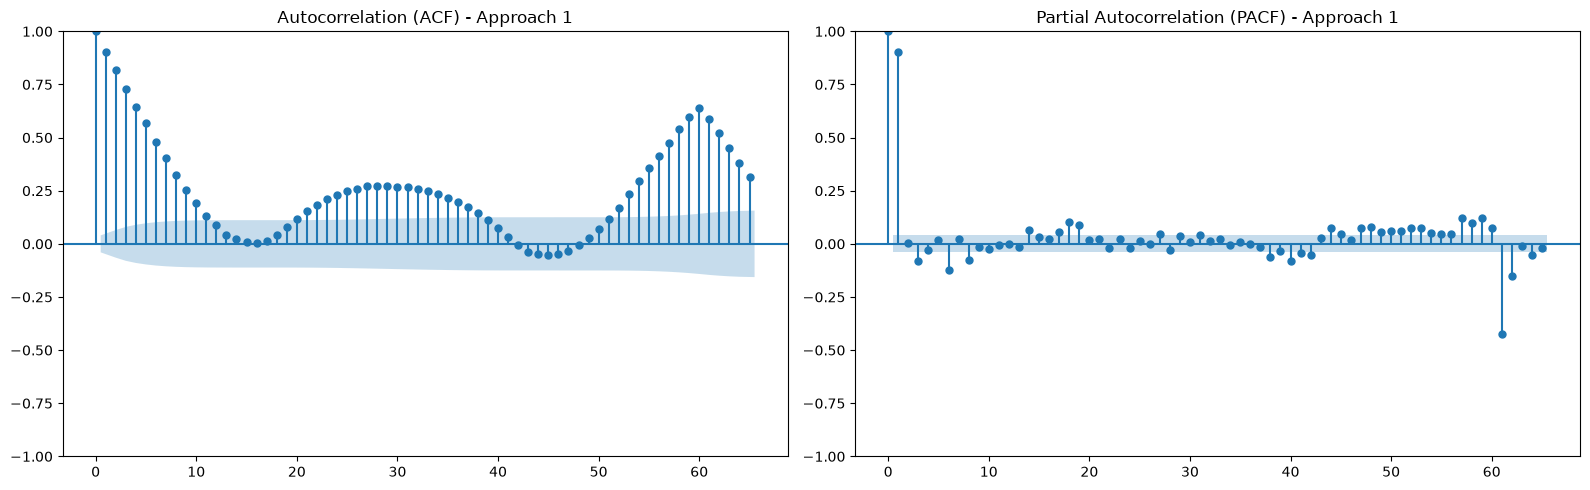

In [17]:
# 2. Plot Autocorrelation (ACF) and Partial Autocorrelation (PACF)
# We use lags=65 so we can see past the 60-interval daily cycle
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(series, lags=65, ax=axes[0], title="Autocorrelation (ACF) - Approach 1", alpha=0.05)
plot_pacf(series, lags=65, ax=axes[1], title="Partial Autocorrelation (PACF) - Approach 1", alpha=0.05)

plt.tight_layout()
plt.show()